# 01 · Piso y techo; revisar falsos planos de pared
Conservamos RANSAC numpy y la unión de parches bajos para el piso. El error anterior fue llamar pared a un bbox grande de puntos dispersos del truss. Ahora proyectamos los inliers a un sistema tangente y medimos celdas ocupadas de 0.30 m: exigimos área ocupada≥20 m² y cobertura≥55%. Un rectángulo grande vacío no cumple. No usamos etiquetas para tomar esa decisión.

La curva de distancia conserva el umbral 0.08 m. Dibujamos también el área y cobertura de los candidatos verticales, con los límites declarados. Rechazar una pared real escasamente observada sigue siendo posible.

**Ejecución:** IPython en `.venv`, celdas en orden, sin kernel de sockets (nbconvert bloqueado por sandbox). Tiempo: 4.38 s. Logs en `outputs/logs/`; cachés en `outputs/cache/`.

In [1]:
import os, sys, json, time
from pathlib import Path
sys.dont_write_bytecode = True
ROOT = Path.cwd() if Path('src/pcseg').exists() else Path.cwd().parents[1]
sys.path.insert(0,str(ROOT/'src'))
os.environ['MPLCONFIGDIR']=str(ROOT/'outputs/cache/exp_matplotlib')
os.environ['IPYTHONDIR']=str(ROOT/'outputs/cache/exp_ipython')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from pcseg.io import read_ply, write_ply, labels_to_rgb
from pcseg.features import voxel_downsample, build_features
from pcseg.metrics import silhouette_sample, davies_bouldin
from pcseg.stages import *
plt.switch_backend('Agg')
thread_limit = threadpool_limits(limits=2)
OUT=ROOT/'outputs'; CACHE=OUT/'cache'; FIG=OUT/'figs'; LOG=OUT/'logs'; ENT=ROOT/'entregable'; ENT.mkdir(exist_ok=True)
START=time.perf_counter()
cloud=read_ply(ROOT/'data/FARO_Scan_Full_Sub1_down3_with_normals.ply')
common_idx=np.load(OUT/'sample_idx.npy')
xyz,rgb,normals=(cloud[k][common_idx] for k in ('xyz','rgb','normals'))
EVAL=build_features(xyz,rgb,normals,use_rgb=True,use_normals=True,use_height=True)
base_table=pd.read_csv(ENT/'clase_metricas.csv')
base=base_table[base_table.seleccionada].iloc[0]
base_labels=np.load(LOG/'clase_labels'/f'{base.id}.npy')
assert len(xyz)==93903 and len(cloud['xyz'])==1647021
print('Muestra común',len(xyz),'Python',sys.executable,sys.version.split()[0])
CLASS_COLORS={'piso':(70,155,70),'techo':(90,140,230),'pared':(190,145,90),
 'plano_horizontal':(145,190,220),'columna':(230,60,55),'viga_horizontal':(245,170,35),
 'viga_o_tuberia':(225,125,25),'tuberia':(25,180,185),
 'equipo_bajo':(155,75,190),'compacto_plausible':(30,200,190),
 'mezcla_no_identificada':(210,110,160),'ruido':(45,45,45)}
def view(points,labels,name,title,classes=None):
    idx=np.random.default_rng(0).choice(len(points),min(35000,len(points)),replace=False)
    p=points[idx]; ls=labels[idx]
    if classes is None: colors=labels_to_rgb(ls)/255.
    else: colors=np.array([CLASS_COLORS[classes[int(v)]] for v in ls])/255.
    fig=plt.figure(figsize=(16,5))
    for i,j in enumerate((1,2)):
        ax=fig.add_subplot(1,3,i+1)
        ax.scatter(p[:,0],p[:,j],c=colors,s=2,alpha=.65,linewidths=0)
        ax.set(xlabel='x (m)',ylabel='y (m)' if j==1 else 'z (m)',aspect='equal',title='Superior' if j==1 else 'Lateral')
    ax=fig.add_subplot(1,3,3,projection='3d'); ax.scatter(*p.T,c=colors,s=1,alpha=.65)
    ax.set(xlabel='x',ylabel='y',zlabel='z',title='3D'); ax.set_box_aspect(np.maximum(np.ptp(p,axis=0),.1))
    if classes:
        names=sorted(set(classes.values()))
        fig.legend(handles=[Patch(color=np.array(CLASS_COLORS[n])/255,label=n) for n in names],loc='lower center',ncol=4,fontsize=8)
    fig.suptitle(title); fig.tight_layout(rect=(0,.12,1,.94) if classes else (0,0,1,.94))
    path=FIG/f'exp_{name}.png'; fig.savefig(path,dpi=140); plt.close(fig); display(Image(filename=str(path)))
def save_run(name,run):
    np.savez_compressed(CACHE/f'exp_{name}.npz',labels=run['labels'],idx=run['idx'],sample_labels=run['sample_labels'])
    serial=[]
    for p in run['planes']:
        serial.append({k:v for k,v in p.items() if k!='inliers'})
    (CACHE/f'exp_{name}_planes.json').write_text(json.dumps(serial,indent=2))
    supports={f'plano_{j}':run['idx'][p['inliers']] for j,p in enumerate(run['planes'])}
    sampled=cloud['xyz'][run['idx']]
    for j,p in enumerate(run['planes']):
        for k,coef in enumerate(p.get('patches',[])):
            mask=np.abs(sampled@np.asarray(coef[:3])+coef[3])<.08
            supports[f'plano_{j}_parche_{k}']=run['idx'][mask]
    np.savez_compressed(CACHE/f'exp_{name}_inliers.npz',**supports)
def load_run(name):
    a=dict(np.load(CACHE/f'exp_{name}.npz'))
    a['planes']=json.loads((CACHE/f'exp_{name}_planes.json').read_text())
    return a
def finish(name, payload):
    payload['segundos_notebook']=time.perf_counter()-START
    (CACHE/f'exp_resumen_{name}.json').write_text(json.dumps(payload,indent=2,default=float))
    print(payload)

from pcseg.propagate import propagate_labels
from sklearn.preprocessing import StandardScaler
BASE_FULL=propagate_labels(xyz,base_labels,cloud['xyz'])
def maps_and_totals(run):
    desc,totals=summarize_classes(cloud['xyz'],run['labels'],run['planes'])
    classes=dict(zip(desc.id,desc.clase_heuristica)); classes[-1]='ruido'
    return desc,totals,classes
def mixture_metrics(desc,totals):
    def pct(name):
        row=totals[totals.clase_heuristica==name]
        return float(row.porcentaje.sum())
    columns=desc[desc.clase_heuristica=='columna']
    high=columns[columns.extension_vertical>=5]
    from sklearn.cluster import DBSCAN
    xy=(high[['x_min','y_min']].to_numpy()+high[['x_max','y_max']].to_numpy())/2
    footprints=DBSCAN(eps=1.5,min_samples=1).fit_predict(xy) if len(high) else []
    distinct=len(set(footprints))
    return dict(n_segmentos_completo=int((desc.id>=0).sum()),mezcla_pct=pct('mezcla_no_identificada'),ruido_completo_pct=pct('ruido'),
        no_resuelto_pct=pct('mezcla_no_identificada')+pct('ruido'),
        n_columnas=int(len(columns)),n_columnas_altas=int((columns.extension_vertical>=5).sum()),n_columnas_altas_distintas=distinct)
def geometry_space():
    path=CACHE/'exp_features_geo.npy'
    if path.exists(): return np.load(path)
    f=local_pca_features(xyz,k=96)
    X=StandardScaler().fit_transform(np.c_[xyz,normals,f['linealidad']])
    np.save(path,X)
    return X


Muestra común 93903 Python /home/evssz/UTEC/6to/machine/clasifica-puntos-pe/.venv/bin/python 3.12.15


,area_bbox,area_ocupada,cobertura_grid,aceptada,n_inliers
0,231.662577,43.56,0.184311,False,1419
1,285.364289,35.73,0.122834,False,992


,umbral,planos_pct,piso_en_un_segmento,piso_n_segmentos,piso_soporte,plano_0_pct,plano_1_pct
0,0.03,29.476248,79.626300,1,488252,23.604860,5.871388
1,0.05,33.682023,92.289433,1,488252,27.358789,6.323234
2,0.08,36.415686,100.000000,1,488252,29.644552,6.771134
3,0.10,37.281795,100.000000,1,488252,30.238230,7.043565
4,0.15,38.623369,100.000000,1,488252,30.914117,7.709252


,id,clase,porcentaje,n_puntos,residual_p95_m,area_ocupada,cobertura_grid
0,0,piso,29.644552,488252,0.057227,517.32,0.526133
1,1,techo,6.771134,111522,0.056777,164.34,0.278566


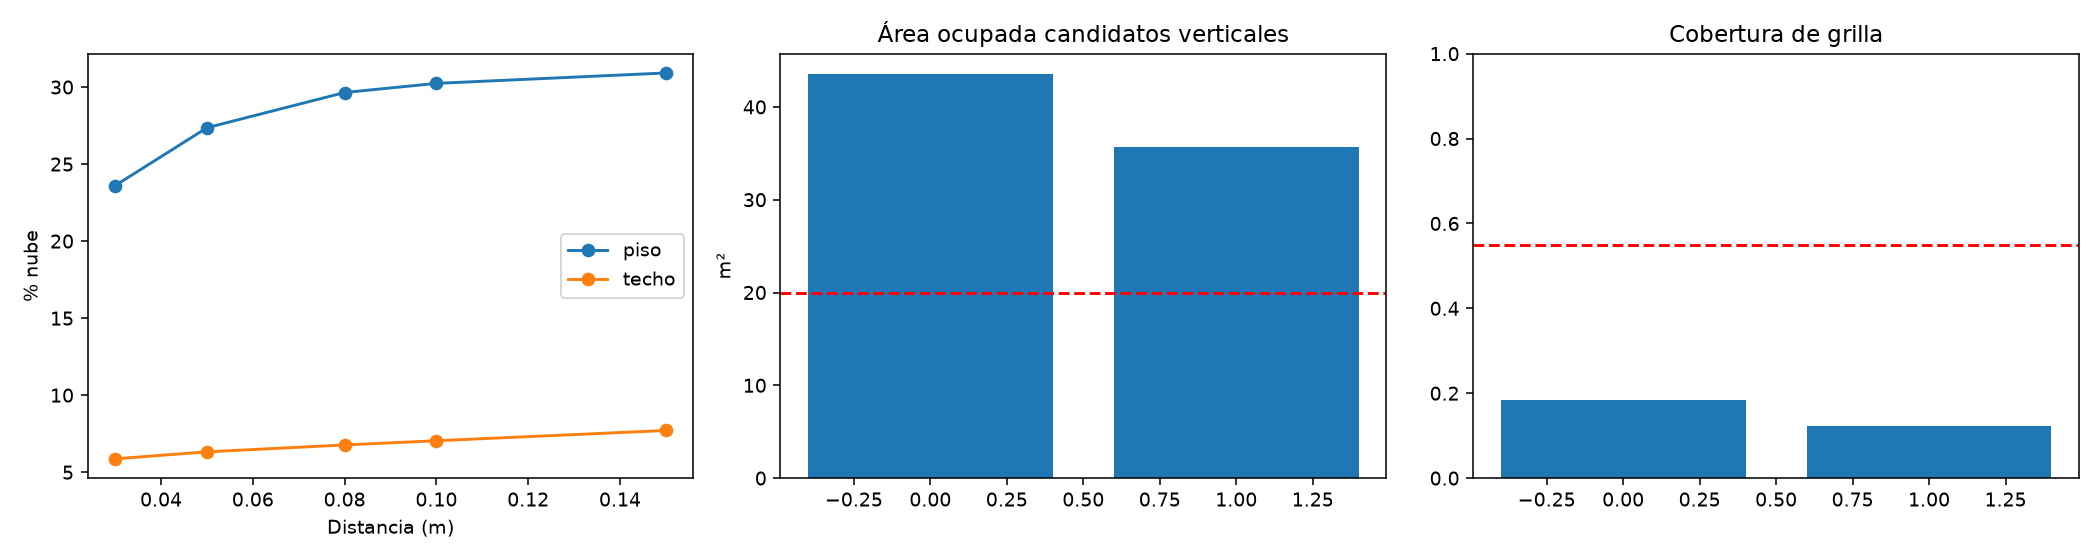

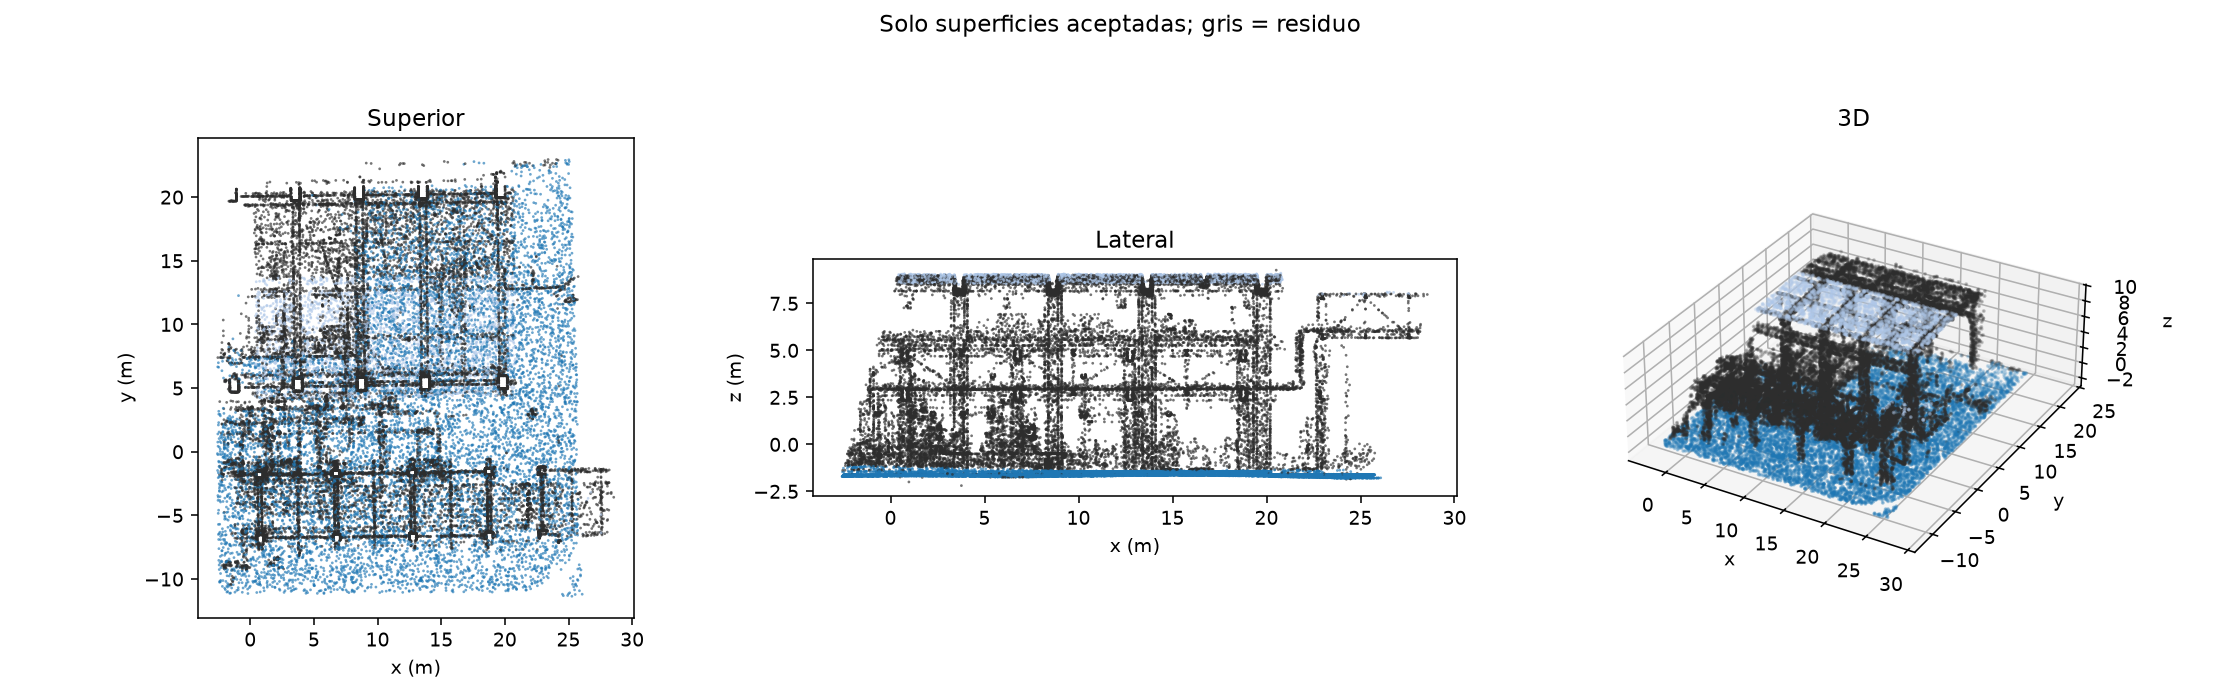

{'n_planos': 2, 'n_paredes': 0, 'n_candidatos_pared': 2, 'piso_en_un_segmento': np.float64(100.0), 'piso_n_segmentos': 1, 'piso_soporte': 488252, 'segundos_notebook': 4.398497833997681}


In [2]:
idx=voxel_downsample(cloud['xyz'],.15)
p=cloud['xyz'][idx]; n=cloud['normals'][idx]; diagnostic=[]
planes=extract_planes(p,n,.08,diagnostics=diagnostic)
wall=pd.DataFrame(diagnostic);wall.to_csv(OUT/'exp_paredes_auditoria.csv',index=False);display(wall)
rows=[]
for threshold in (.03,.05,.08,.10,.15):
    labels=assign_planes(cloud['xyz'],planes,threshold)
    row={'umbral':threshold,'planos_pct':100*np.mean(labels>=0),**floor_metrics(cloud['xyz'],labels,planes)}
    for j in range(len(planes)):row[f'plano_{j}_pct']=100*np.mean(labels==j)
    rows.append(row)
sensitivity=pd.DataFrame(rows);sensitivity.to_csv(OUT/'exp_sensibilidad_planos.csv',index=False);display(sensitivity)
labels=assign_planes(cloud['xyz'],planes,.08)
plane_rows=[]
for j,pl in enumerate(planes):
    mask=labels==j
    plane_rows.append(dict(id=j,clase=pl['class'],porcentaje=100*mask.mean(),n_puntos=int(mask.sum()),
        residual_p95_m=float(np.quantile(plane_distance(cloud['xyz'][mask],pl),.95)),
        area_ocupada=pl.get('area_ocupada',np.nan),cobertura_grid=pl.get('cobertura_grid',np.nan)))
table=pd.DataFrame(plane_rows);table.to_csv(OUT/'exp_planos.csv',index=False);display(table)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for j,pl in enumerate(planes):axes[0].plot(sensitivity.umbral,sensitivity[f'plano_{j}_pct'],'o-',label=pl['class'])
axes[0].set(xlabel='Distancia (m)',ylabel='% nube');axes[0].legend()
if len(wall):
    axes[1].bar(np.arange(len(wall)),wall.area_ocupada);axes[1].axhline(20,c='r',ls='--')
    axes[2].bar(np.arange(len(wall)),wall.cobertura_grid);axes[2].axhline(.55,c='r',ls='--')
axes[1].set(title='Área ocupada candidatos verticales',ylabel='m²');axes[2].set(title='Cobertura de grilla',ylim=(0,1))
path=FIG/'exp_01_sensibilidad.png';fig.tight_layout();fig.savefig(path,dpi=140);plt.close(fig);display(Image(filename=str(path)))
run=dict(labels=labels,idx=idx,sample_labels=assign_planes(p,planes,.08),planes=planes)
save_run('estructura',run)
view(cloud['xyz'],labels,'01_estructura','Solo superficies aceptadas; gris = residuo')
finish('01',dict(n_planos=len(planes),n_paredes=int(sum(pl['class']=='pared' for pl in planes)),
    n_candidatos_pared=len(wall),**floor_metrics(cloud['xyz'],labels,planes)))

## Qué aprendimos / qué falló
Con los números delante, los dos supuestos planos de pared tenían área ocupada de **43.56 y 35.73 m²**, pero cobertura de solo **18.43% y 12.28%**. El bbox grande estaba casi vacío: era acero disperso. Ambos quedan rechazados y no exportamos ninguna pared. El área por sí sola habría vuelto a cometer el error; la cobertura de grilla fue necesaria. Una pared real muy ocluida también podría rechazarse, así que esto sigue siendo una heurística.

Conservamos **488 252 puntos de piso (29.64%)** en un segmento con tres parches y **111 522 puntos de techo (6.77%)**. Umbral 0.08 m y residual p95 del piso≈0.0572 m. El porcentaje unido se refiere al soporte geométrico que definimos, no a recall real. Los puntos antes absorbidos como pared vuelven al residuo para que la orientación los separe.